In [1]:
from aotools import zernike
from matplotlib import pyplot as plt
import numpy as np
from aotools.turbulence import infinitephasescreen

%matplotlib inline

In [2]:
#n:   0 1 2 3  4  5  6   7   8   9   10   11   12   13    14    15    16
#2^n: 1 2 4 8 16 32 64 128 256 512 1024 2048 4096 8192 16384 32768 65536

#???suggested zernike<scrn_size*pixel_scale/2r0????
#radialDegree    1   2   3    4   5   6   7   8   9  10  11  12  13  14  15  16  17  18  19  20  21  22  23  24
#zernike(approx) 1   3   6   10  15  21  28  36  45  55  66  78  91 105 120 136 153 171 190 210 231 253 276 300

scrn_size=128 #pixel; int; for the whole phase screen; total pixel number = scrn_size*scrn_size pixel
radialDegree=16 #int; piston = 1, tip/tilt=2, focus/defocus/astigmatism=3, 2trefoils/2comas=4, ...
Nzernike=int(radialDegree*(radialDegree+1)/2) #total number of zernike modes within given radial degree
pixel_scale=0.1 #m/pixel
r0=0.1 #m
L0=20.0 #m

color_map = plt.cm.get_cmap('Blues')
reversed_color_map = color_map.reversed()

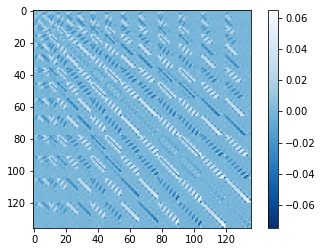

<Figure size 432x288 with 0 Axes>

In [17]:
## 3 ## Make circular pupil ##
#inside pupil=1=true, outside=0=false
#pupil --> 2d array
#plat_pupil --> flatten 2d array

x=np.arange(scrn_size)
x=x-scrn_size/2
xx,yy=np.meshgrid(x,x)
r=np.sqrt(xx**2+yy**2)
pupil=np.zeros(r.shape) # inside circle=1=True
for i in range(r.shape[0]):
    for j in range(r.shape[1]):
        if r[i,j]<=scrn_size/2:
            pupil[i,j]=1
        else:
            pupil[i,j]=0
            
flat_pupil=pupil.flatten()

#Zernike Modes (not exactly orthonormal); this wants to be Z_i which is the original zernike,
                                        # however we can only generate z_i which is the Z_i wanna be
flat_modes=[]
modes=zernike.zernikeArray(Nzernike,scrn_size)
for i in np.arange(Nzernike):
    flat_modes.append((pupil*modes[i]).flatten())

# Make orthonormal matrix --> c_ij=<z_i,z_j>=z_i dot z_j
orthonormality=np.zeros((Nzernike,Nzernike))

area=np.pi*(scrn_size/2)**2

# Normality
#for i in np.arange(Nzernike):
#    orthonormality[i,i]=np.dot(flat_modes[i],flat_modes[i])/area

# Orthogonality
for i in np.arange(Nzernike):
    for j in np.arange(Nzernike):
        if i!=j:
            if i<j:
                orthonormality[i,j]=np.dot(flat_modes[i],flat_modes[j])/area
                orthonormality[j,i]=orthonormality[i,j]

plt.imshow(orthonormality,cmap=reversed_color_map)
plt.colorbar()
plt.show()
plt.clf()

In [4]:
#Want orthonormalized bases -- z'_i which is orthonormalized z_i
#Z_i=original zernike         -->  orthonormalized but impossible to make
#z_i=replicated zernike       -->  close enough to zernike but not orthonormalized
#z'_i=orthonormalized z_i     -->  close enough to zernike and orthonormalized

#create a function which take in set of not orthonormal bases  -->  z_i
#                  then  return set of orthonormalized bases   -->  z'_i

#https://en.wikipedia.org/wiki/Gram%E2%80%93Schmidt_process

v=flat_modes
N=len(v)
u=[]
e=[]
for i in np.arange(N):
    if i==0:
        u.append(v[0])
    else:
        u.append(v[i])
        for j in np.arange(i):
            u[i]=u[i]-(np.dot(u[j],v[i])/np.dot(u[j],u[j]))*u[j]
            
for i in np.arange(N):
    e.append(u[i]/np.sqrt(np.dot(u[i],u[i])))

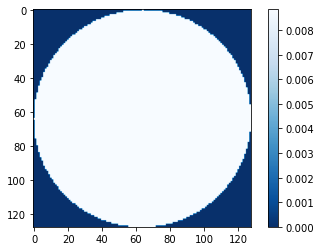

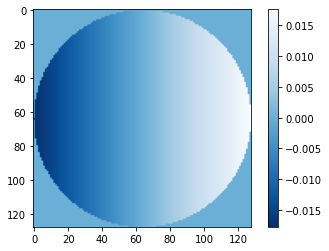

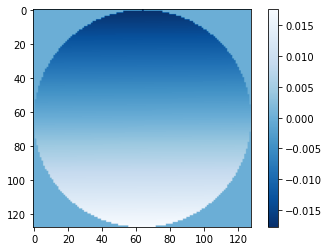

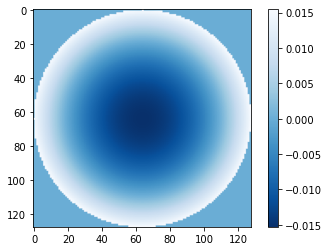

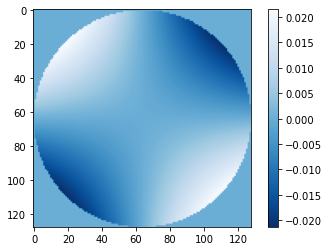

...

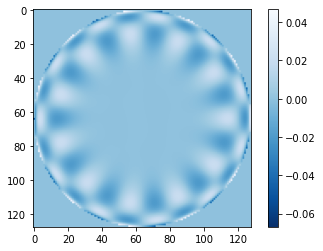

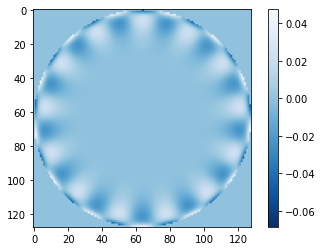

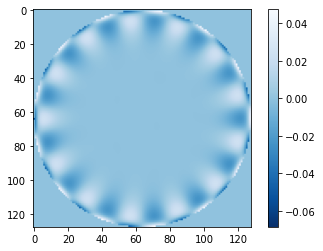

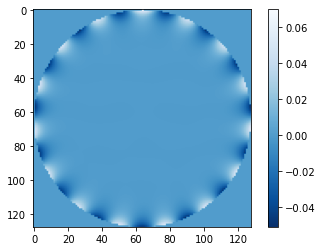

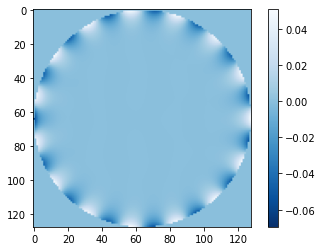

<Figure size 432x288 with 0 Axes>

In [5]:
for i in np.arange(N):
    plt.imshow(e[i].reshape((scrn_size,scrn_size)),cmap=reversed_color_map)
    plt.colorbar()
    plt.show()
    plt.clf()


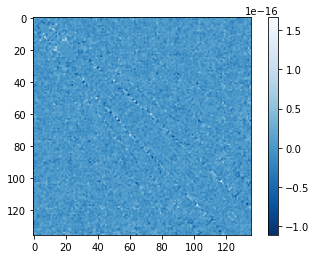

<Figure size 432x288 with 0 Axes>

In [18]:
# Make orthonormal matrix --> c_ij=<z_i,z_j>=z_i dot z_j
orthonormality=np.zeros((Nzernike,Nzernike))

# Normality
#for i in np.arange(Nzernike):
#    orthonormality[i,i]=np.dot(e[i],e[i])

# Orthogonality
for i in np.arange(Nzernike):
    for j in np.arange(Nzernike):
        if i!=j:
            if i<j:
                orthonormality[i,j]=np.dot(e[i],e[j])
                orthonormality[j,i]=orthonormality[i,j]

plt.imshow(orthonormality,cmap=reversed_color_map)
plt.colorbar()
plt.show()
plt.clf()

C:\Users\gqmc62\Anaconda3\lib\site-packages\ipykernel_launcher.py:2: RuntimeWarning: invalid value encountered in true_divide
  


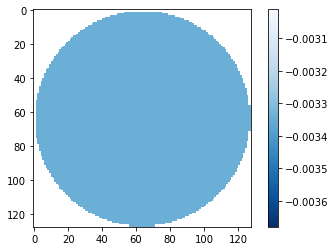

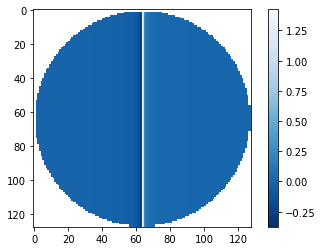

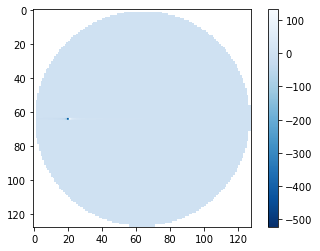

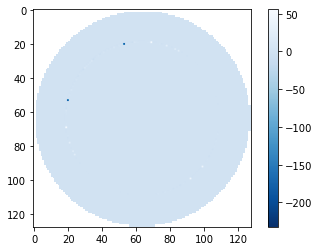

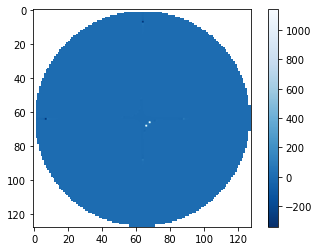

...

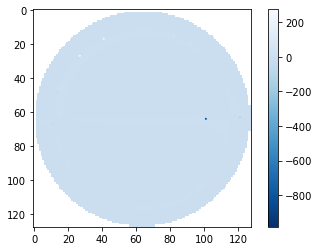

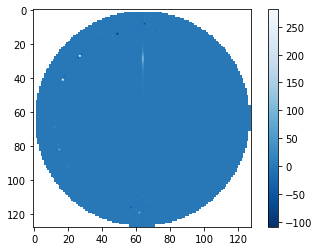

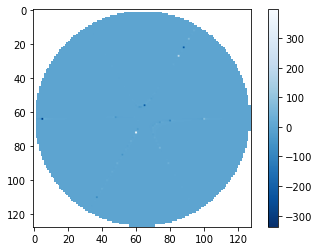

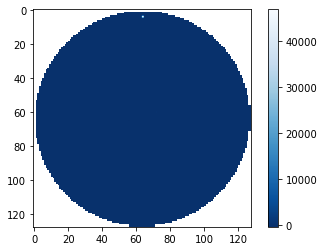

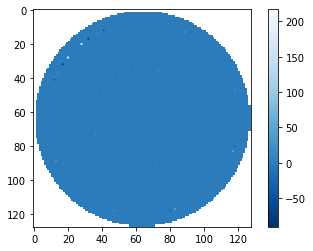

C:\Users\gqmc62\Anaconda3\lib\site-packages\ipykernel_launcher.py:2: RuntimeWarning: divide by zero encountered in true_divide
  


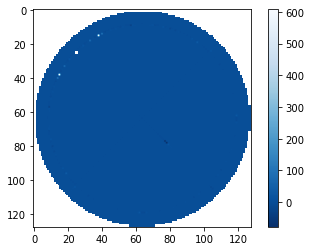

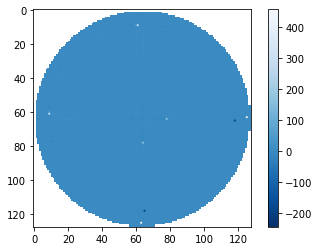

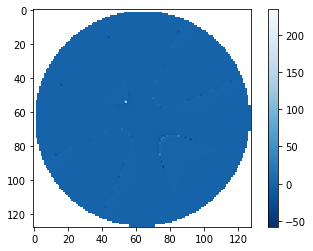

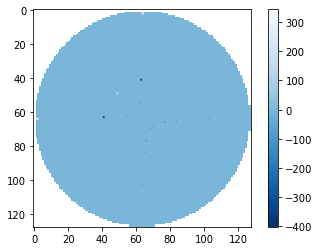

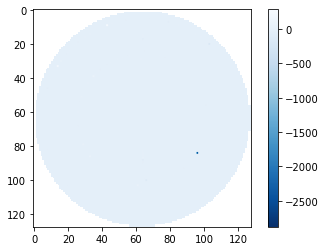

...

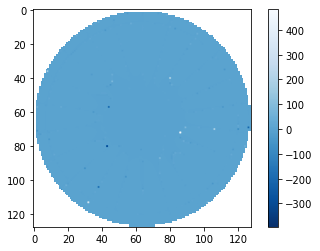

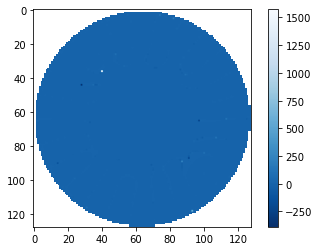

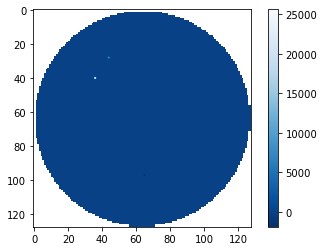

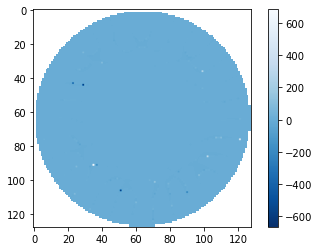

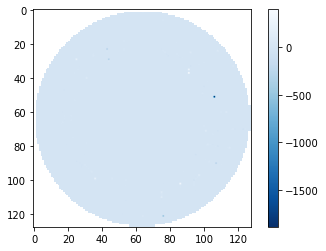

<Figure size 432x288 with 0 Axes>

In [7]:
for i in np.arange(N):
    plt.imshow(((flat_modes[i]/np.sqrt(area)-e[i])/e[i]).reshape((scrn_size,scrn_size)),cmap=reversed_color_map)
    plt.colorbar()
    plt.show()
    plt.clf()

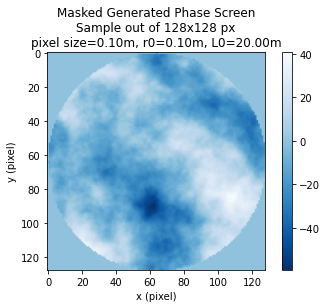

<Figure size 432x288 with 0 Axes>

In [8]:
## 5 ## Generate phase screen ##
#phase screen was actually generated in the last section
phase_screen=infinitephasescreen.PhaseScreenVonKarman(scrn_size,pixel_scale,r0,L0)
phase=phase_screen.scrn
flat_phase=phase.flatten()



#plots

plt.imshow(phase*pupil,cmap=reversed_color_map)
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.title('Masked Generated Phase Screen\nSample out of {:d}x{:d} px\npixel size={:.2f}m, r0={:.2f}m, L0={:.2f}m'.format(scrn_size,scrn_size,pixel_scale,r0,L0))
plt.savefig('sample-phase-screen')
plt.colorbar()
plt.show()
plt.clf()

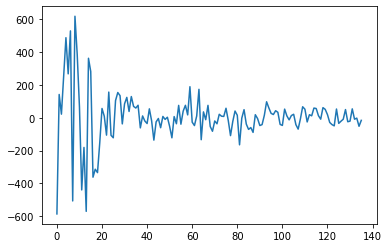

<Figure size 432x288 with 0 Axes>

In [9]:
coeffs=np.zeros(Nzernike) #coeffs[sample,mode]
for j in range(Nzernike):
    coeffs[j]=np.dot(flat_pupil*flat_phase,e[j])
    
plt.plot(np.arange(Nzernike),coeffs)
plt.show()
plt.clf()

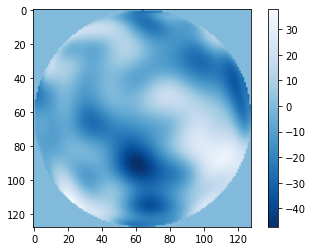

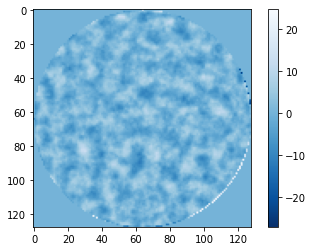

<Figure size 432x288 with 0 Axes>

In [11]:
calculate=np.zeros(scrn_size*scrn_size)
for i in np.arange(Nzernike):
    calculate=calculate+coeffs[i]*e[i]
    
plt.imshow(calculate.reshape(scrn_size,scrn_size),cmap=reversed_color_map)
plt.colorbar()
plt.show()
plt.clf()

residue=flat_pupil*(flat_phase-calculate)
plt.imshow(residue.reshape(scrn_size,scrn_size),cmap=reversed_color_map)
plt.colorbar()
plt.show()
plt.clf()

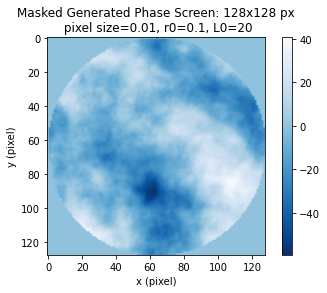

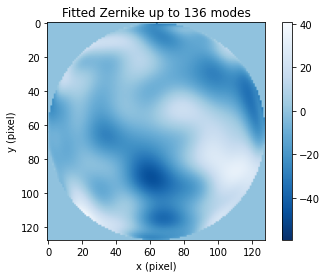

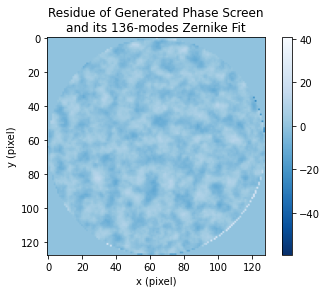

observe rms=
15.992139184020115
fit rms=
15.513997617537143
residue rms=
3.839171185784031


<Figure size 432x288 with 0 Axes>

In [15]:
observe=pupil*phase

mapmax=observe.max()
mapmin=observe.min()

plt.imshow(observe,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.title('Masked Generated Phase Screen: 128x128 px\n pixel size=0.01, r0=0.1, L0=20')
plt.colorbar()
plt.savefig('PhaseScreen')
plt.show()
plt.clf()

plt.imshow(calculate.reshape(scrn_size,scrn_size),cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
plt.colorbar()
plt.title('Fitted Zernike up to {:d} modes'.format(Nzernike))
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.savefig('FittedZernike')
plt.show()
plt.clf()


plt.imshow(residue.reshape(scrn_size,scrn_size),cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
plt.colorbar()
plt.title('Residue of Generated Phase Screen\nand its {:d}-modes Zernike Fit'.format(Nzernike))
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.savefig('Residue')
plt.show()
plt.clf()

obs_rms=0.
calc_rms=0.
res_rms=0.

obs_n=pupil.sum()
calc_n=pupil.sum()
res_n=pupil.sum()

obs_mean=(pupil*observe).sum()/obs_n
calc_mean=(pupil*calculate.reshape(scrn_size,scrn_size)).sum()/calc_n
res_mean=(pupil*residue.reshape(scrn_size,scrn_size)).sum()/res_n

for i in np.arange(scrn_size):
    for j in np.arange(scrn_size):
        if pupil[i,j]==1:
            obs_rms=obs_rms+(observe[i,j]-obs_mean)**2
            calc_rms=calc_rms+(calculate.reshape(scrn_size,scrn_size)[i,j]-calc_mean)**2
            res_rms=res_rms+(residue.reshape(scrn_size,scrn_size)[i,j]-res_mean)**2
            
obs_rms=np.sqrt(obs_rms/(obs_n-1))
calc_rms=np.sqrt(calc_rms/(calc_n-1))
res_rms=np.sqrt(res_rms/(res_n-1))

print('observe rms=')
print(obs_rms)
print('fit rms=')
print(calc_rms)
print('residue rms=')
print(res_rms)